# Short-Term Load Forecasting (STLF) for Power Grids


## 1. Project Objective

**What is STLF?** Predicting how much electricity people will use in the near future. Here we predict **the next day's electricity demand** for the PJME region (eastern part of the PJM grid, USA).

**Why does it matter?** Electricity is hard to store, so a grid operator must produce almost exactly what people use. Under-forecasting risks shortages; over-forecasting wastes fuel and money.

**What do we do?** We turn hourly readings into one number per day (daily energy in MWh) and compare **three** forecasting approaches on exactly the same test days:

| # | Model | Idea in one line |
|---|-------|------------------|
| 1 | **Naive** (baseline) | "Tomorrow = today" |
| 2 | **Seasonal Naive** (baseline) | "Tomorrow = the same weekday last week" |
| 3 | **ARIMA** | Statistical model built from past values and past errors |

**Story of the notebook:**
Data -> Daily series + Train/Test split -> EDA (incl. Year-over-Year) -> ACF/PACF -> ADF stationarity test -> Naive / Seasonal Naive -> ARIMA -> Comparison -> Actual vs Predicted -> Residuals -> Conclusion

## 2. Import Libraries

* `numpy`, `pandas` - numbers and tables
* `matplotlib`, `seaborn` - graphs
* `statsmodels` - ACF/PACF plots, ADF test, ARIMA
* `scikit-learn` - error metrics

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')   # keeps the output clean
sns.set_style('whitegrid')

## 3. Load and Prepare the Data

The file `PJME_hourly.csv` must be in the same folder as this notebook. It has two columns:

* `Datetime` - timestamp of each hourly reading
* `PJME_MW` - electricity demand in megawatts (the target)

There are no other predictor columns, so the models can only use the date and the demand history itself.

**Time order matters:** a forecast uses "yesterday", so we sort by time and use the date as the index.

In [ ]:
df = pd.read_csv('PJME_hourly.csv', parse_dates=['Datetime'])   # parse_dates turns text into real dates
df = df.set_index('Datetime').sort_index()                      # time order + date as index

print("Hourly rows:", len(df))
print("First / last timestamp:", df.index.min(), "/", df.index.max())
print("Missing values:", int(df['PJME_MW'].isnull().sum()))
print("Duplicate timestamps:", int(df.index.duplicated().sum()))
display(df.head())

Hourly rows: 145366
First / last timestamp: 2002-01-01 01:00:00 / 2018-08-03 00:00:00
Missing values: 0
Duplicate timestamps: 4


,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


**Hourly -> daily.** We forecast the *next day*, so we need one number per day. Each hourly reading is power (MW) held for one hour, so the day's energy is the average MW x 24 hours = **MWh**.

Using the *average x 24* (instead of a plain sum) keeps days with 23 or 25 readings (daylight-saving changes, missing readings) on the same scale as normal days. A day with almost no readings (fewer than 20) is dropped, and any missing calendar day is filled by straight-line interpolation so that "yesterday" is always exactly one calendar day back.

**Train / test split (chronological):** the **last 90 days** are the test set; everything before is training data. We never shuffle: training on the past and testing on the future is how forecasting works in real life.

Daily series: 6058 days
Date range: 2002-01-01 to 2018-08-02
Train: 5968 days (2002-01-01 to 2018-05-04)
Test:  90 days (2018-05-05 to 2018-08-02)
(Missing days filled by interpolation: 0)


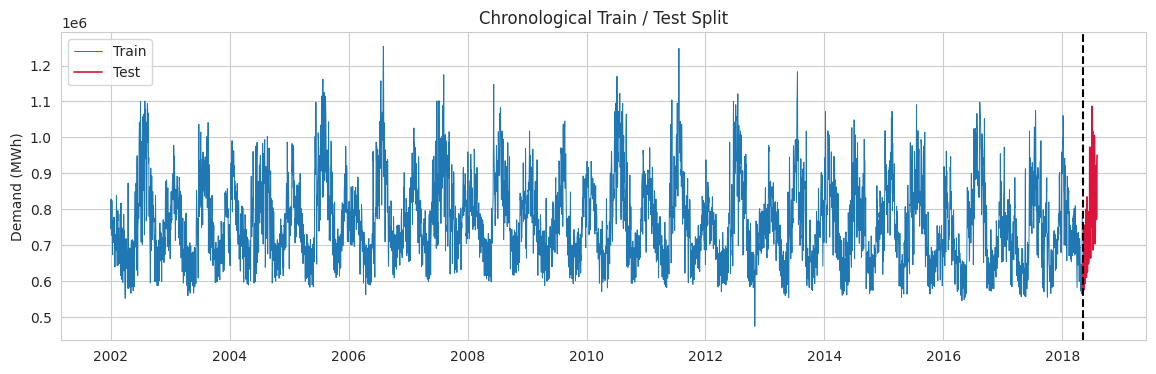

In [ ]:
TEST_DAYS = 90

# 1) Hourly -> daily energy (MWh)
readings_per_day = df['PJME_MW'].resample('D').count()
daily = df['PJME_MW'].resample('D').mean() * 24        # average MW x 24 hours = MWh
daily = daily[readings_per_day >= 20]                  # drop days with (almost) no readings

# 2) Complete calendar: no missing days
calendar = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
n_filled = len(calendar) - len(daily)
daily = daily.reindex(calendar).interpolate()
daily.index.name = 'Date'
daily.name = 'Demand_MWh'

# 3) Chronological train / test split
train = daily.iloc[:-TEST_DAYS]
test = daily.iloc[-TEST_DAYS:]

print(f"Daily series: {len(daily)} days")
print(f"Date range: {daily.index.min().date()} to {daily.index.max().date()}")
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")
print(f"(Missing days filled by interpolation: {n_filled})")

plt.figure(figsize=(14, 4))
plt.plot(train.index, train, label='Train', linewidth=0.7)
plt.plot(test.index, test, label='Test', linewidth=1.2, color='crimson')
plt.axvline(test.index.min(), color='black', linestyle='--')
plt.title('Chronological Train / Test Split')
plt.ylabel('Demand (MWh)')
plt.legend()
plt.show()

## 4. Exploratory Data Analysis (EDA)

All EDA below uses the **training data only**, so the test period stays unseen.

### 4.1 Distribution of daily demand

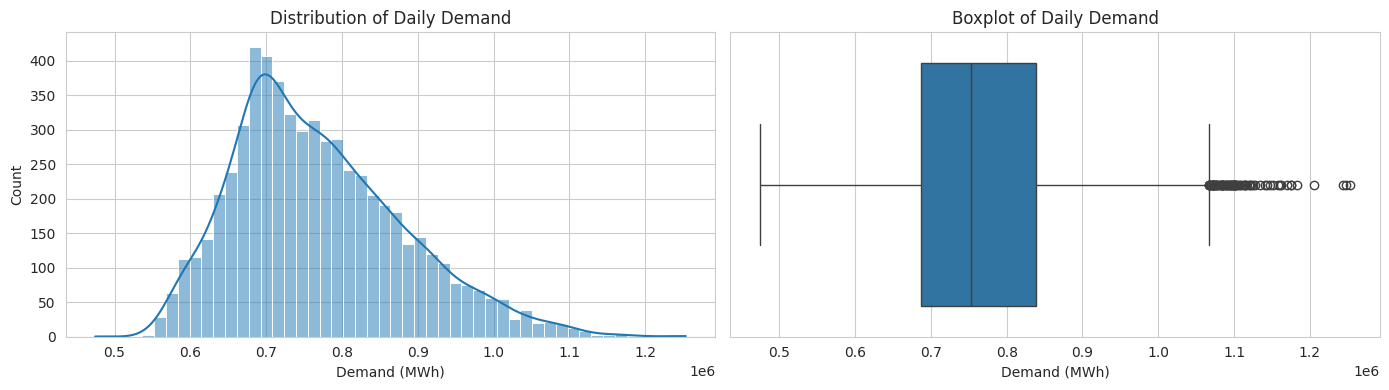

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train, bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Daily Demand')
axes[0].set_xlabel('Demand (MWh)')

sns.boxplot(x=train, ax=axes[1])
axes[1].set_title('Boxplot of Daily Demand')
axes[1].set_xlabel('Demand (MWh)')

plt.tight_layout()
plt.show()

The histogram shows how often each demand level occurs. The box covers the middle 50% of days; dots beyond the whiskers are unusually high days (heat waves / cold snaps). We keep them, because a forecaster must handle them.




### 4.2 Rolling statistics
A **rolling mean** (average of the last *N* days) shows the slowly changing level; a **rolling standard deviation** shows how much the series wiggles. If the mean and spread stay roughly stable, the series has no steady drift.

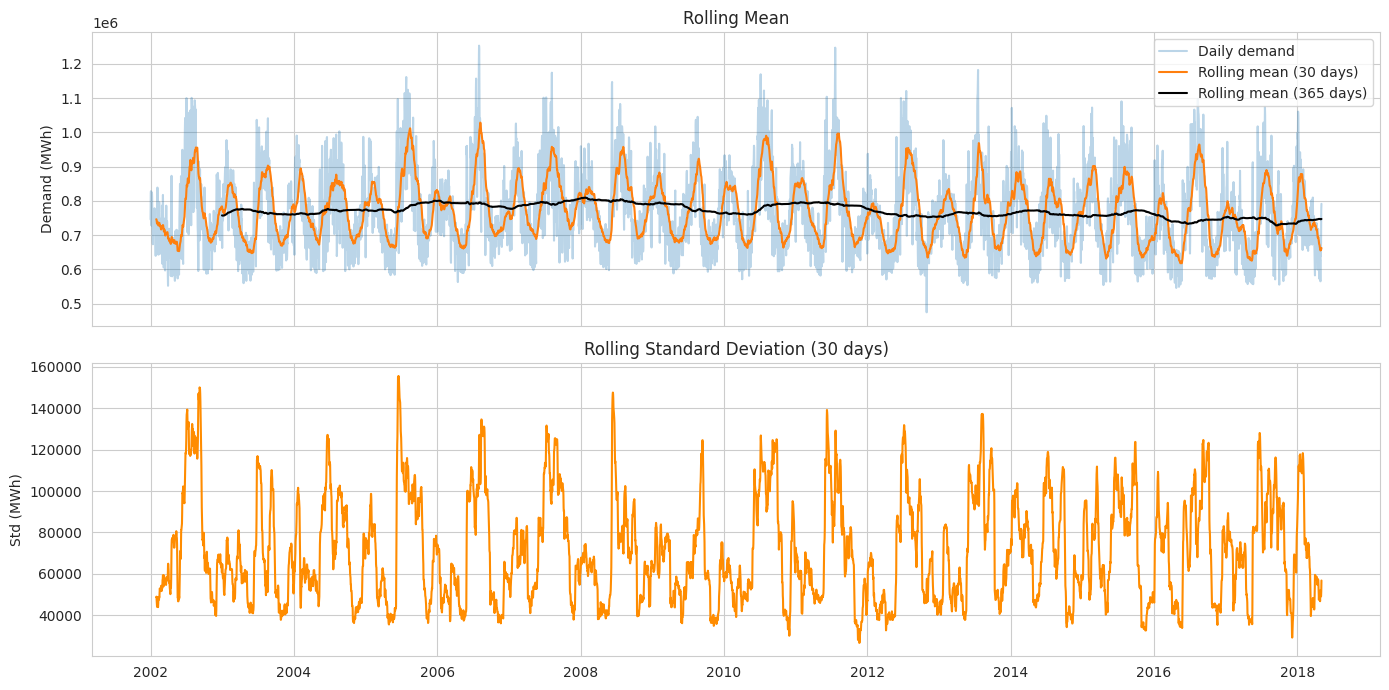

In [ ]:
rolling_mean_30 = train.rolling(30).mean()
rolling_mean_365 = train.rolling(365).mean()
rolling_std_30 = train.rolling(30).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(train.index, train, alpha=0.3, label='Daily demand')
axes[0].plot(train.index, rolling_mean_30, label='Rolling mean (30 days)')
axes[0].plot(train.index, rolling_mean_365, color='black', label='Rolling mean (365 days)')
axes[0].set_ylabel('Demand (MWh)')
axes[0].set_title('Rolling Mean')
axes[0].legend()

axes[1].plot(train.index, rolling_std_30, color='darkorange')
axes[1].set_ylabel('Std (MWh)')
axes[1].set_title('Rolling Standard Deviation (30 days)')

plt.tight_layout()
plt.show()

### Overall Load Over Time

This plot shows the entire daily demand series from beginning to end, giving an overall perspective of the load evolution.

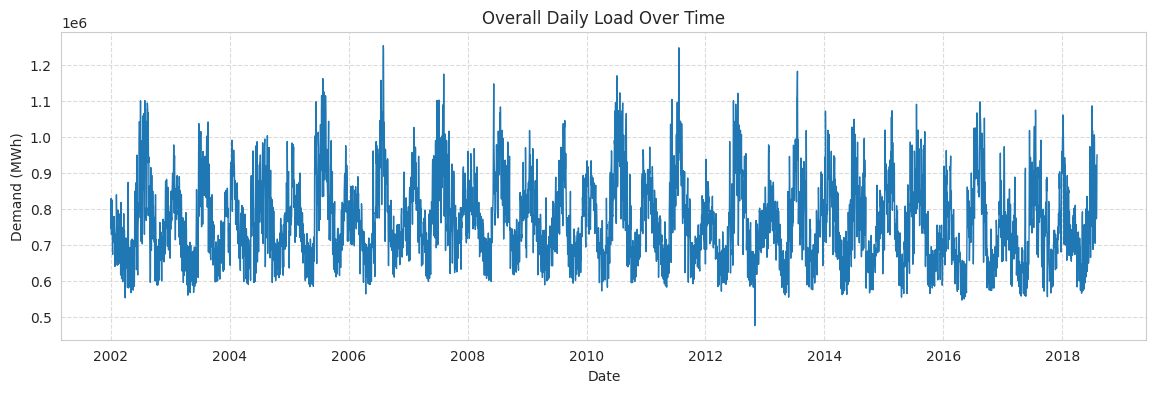

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(daily.index, daily, linewidth=1)
plt.title('Overall Daily Load Over Time')
plt.xlabel('Date')
plt.ylabel('Demand (MWh)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 4.3 Time-based patterns
Average demand by **hour of day** (from the hourly data), **day of week** and **month**. These show the daily, weekly and yearly cycles.

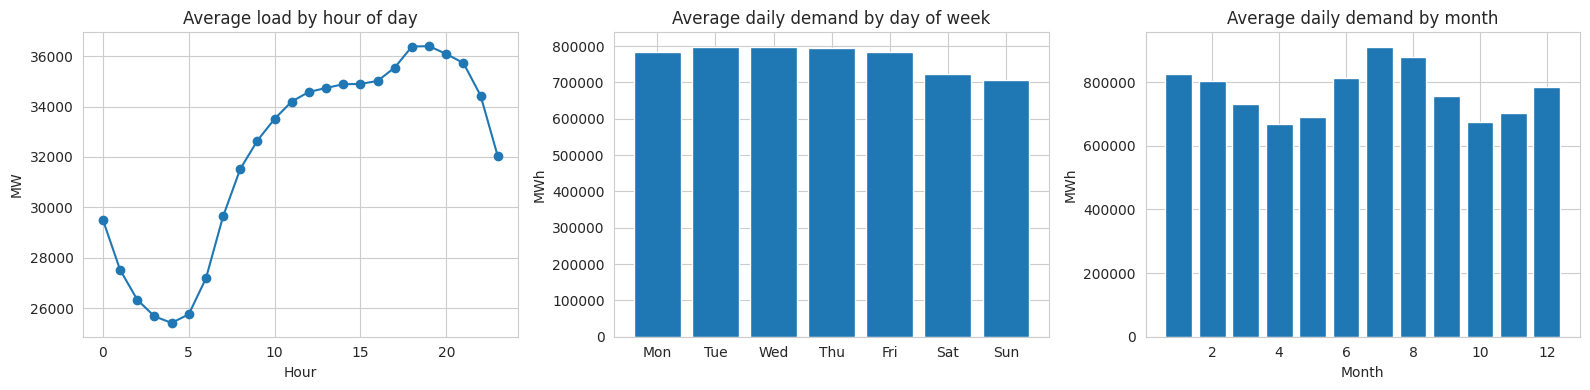

In [ ]:
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
hourly_train = df[df.index < test.index.min()]          # hourly data before the test period

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

hour_pattern = hourly_train.groupby(hourly_train.index.hour)['PJME_MW'].mean()
axes[0].plot(hour_pattern.index, hour_pattern.values, marker='o')
axes[0].set_title('Average load by hour of day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('MW')

weekday_pattern = train.groupby(train.index.dayofweek).mean()
axes[1].bar(day_names, weekday_pattern.values)
axes[1].set_title('Average daily demand by day of week')
axes[1].set_ylabel('MWh')

month_pattern = train.groupby(train.index.month).mean()
axes[2].bar(month_pattern.index, month_pattern.values)
axes[2].set_title('Average daily demand by month')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('MWh')

plt.tight_layout()
plt.show()

* **Daily cycle:** demand changes strongly across the hours of a day.
* **Weekly cycle:** weekends differ from weekdays. This is why a *seasonal naive* baseline (lag 7) and a weekly AR lag in ARIMA make sense.
* **Yearly cycle:** demand changes with the month (heating and cooling seasons).

### 4.4 Year-over-Year Comparison
Does each year look like the one before? **Left:** average daily demand for each month, one line per year. Lines that sit on top of each other mean the yearly pattern repeats. **Right:** percentage change of the yearly average compared with the previous year (complete years only).

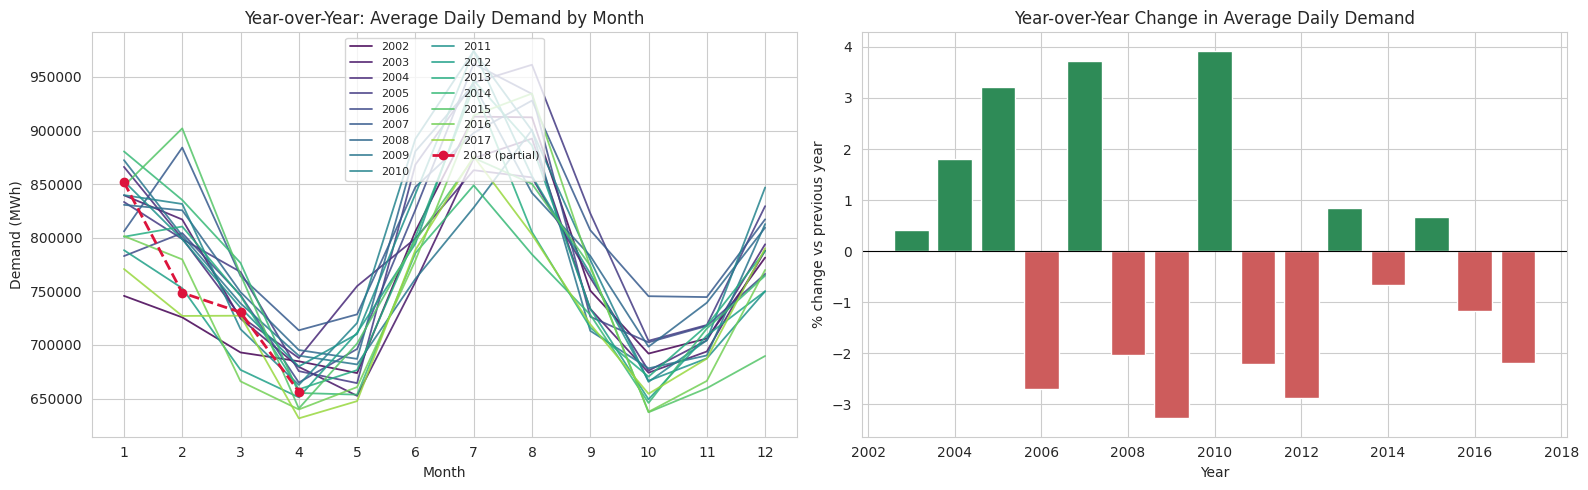

In [ ]:
yoy = train.to_frame('demand')
yoy['year'] = yoy.index.year
yoy['month'] = yoy.index.month

# Average demand per month for every year (rows = month, columns = year)
monthly = yoy.groupby(['year', 'month'])['demand'].mean().unstack(0)

# The last year is usually incomplete: hide its unfinished month so it is not misleading
last_day = train.index.max()
last_year = last_day.year
if last_day != last_day + pd.offsets.MonthEnd(0):
    monthly.loc[last_day.month, last_year] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors = plt.cm.viridis(np.linspace(0, 0.9, monthly.shape[1]))
for color, year in zip(colors, monthly.columns):
    if year == last_year and last_day != pd.Timestamp(f'{year}-12-31'):
        axes[0].plot(monthly.index, monthly[year], color='crimson', linestyle='--', marker='o', linewidth=2, label=f'{year} (partial)')
    else:
        axes[0].plot(monthly.index, monthly[year], color=color, linewidth=1.3, alpha=0.85, label=str(year))
axes[0].set_xticks(range(1, 13))
axes[0].set_title('Year-over-Year: Average Daily Demand by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Demand (MWh)')
axes[0].legend(ncol=2, fontsize=8, loc='upper center')

# Yearly average and % change vs previous year (complete years only)
annual = yoy.groupby('year')['demand'].mean()
complete_years = [y for y in annual.index if y < last_year or last_day == pd.Timestamp(f'{y}-12-31')]
annual = annual.loc[complete_years]
yoy_change = annual.pct_change() * 100
yoy_change = yoy_change.dropna()
axes[1].bar(yoy_change.index, yoy_change.values, color=['seagreen' if v >= 0 else 'indianred' for v in yoy_change.values])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Year-over-Year Change in Average Daily Demand')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('% change vs previous year')

plt.tight_layout()
plt.show()

**How to read it:** the monthly lines follow the same two-hump shape every year (winter and summer peaks), so the *seasonal* pattern is stable. The yearly % changes stay small and move both up and down, so there is no steady long-term trend.

## 5. ACF & PACF Plots

The **AutoCorrelation Function (ACF)** and **Partial AutoCorrelation Function (PACF)** help identify the order of ARIMA models:

* **ACF** shows the correlation between the series and its lagged values
* **PACF** shows the correlation after removing the effect of the intermediate lags
* For **AR(p)**: the PACF cuts off after lag *p*
* For **MA(q)**: the ACF cuts off after lag *q*

The shaded blue band is the "not different from zero" zone. Bars that stick out of the band are significant. We use the **training data only**.

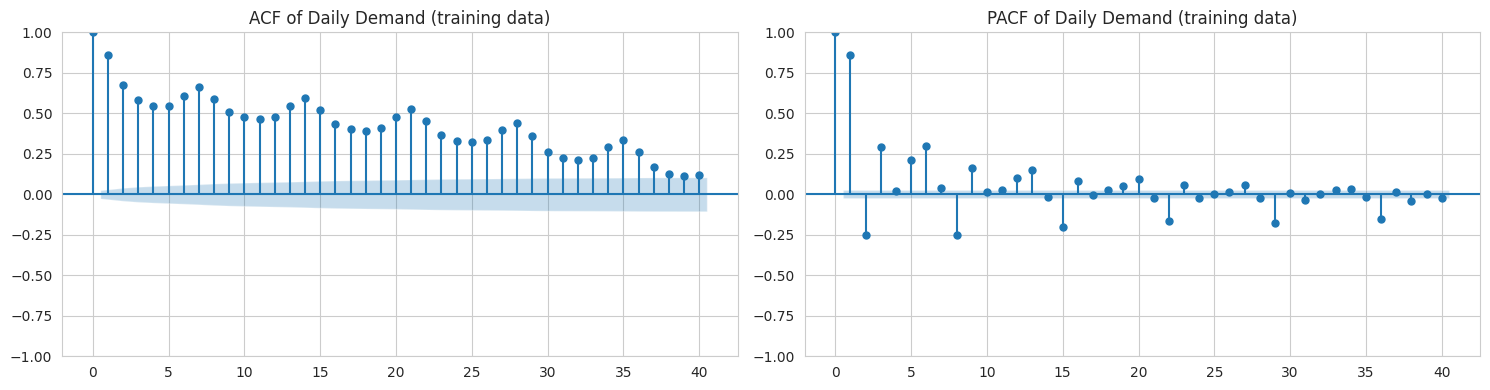

95% band: +/- 0.025
Significant PACF lags (1-14): [1, 2, 3, 5, 6, 7, 8, 9, 12, 13]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(train.values, lags=40, ax=axes[0])
axes[0].set_title('ACF of Daily Demand (training data)')
plot_pacf(train.values, lags=40, method='ywm', ax=axes[1])
axes[1].set_title('PACF of Daily Demand (training data)')
plt.tight_layout()
plt.show()

# Which PACF lags stick out of the 95% band? (used to choose p for ARIMA)
conf = 1.96 / np.sqrt(len(train))
pacf_values = pacf(train.values, nlags=14, method='ywm')
sig_pacf_lags = [k for k in range(1, 15) if abs(pacf_values[k]) > conf]
print(f"95% band: +/- {conf:.3f}")
print("Significant PACF lags (1-14):", sig_pacf_lags)

**How to read these plots here:**

* The **ACF** starts high and decays *slowly*, with small bumps at lags 7, 14, 21 ... (the weekly cycle). It does not cut off sharply, so we keep the MA part of ARIMA small.
* The **PACF** has a big spike at lag 1 and smaller spikes at a few short lags and around lag 7. So the recent days and the weekly lag carry the direct information, which suggests an AR part up to about 7 lags.

## 6. Stationarity Check (ADF Test)

A **stationary** series keeps a stable mean and spread over time. ARIMA works best on stationary data.

**Augmented Dickey-Fuller (ADF) test**

* H0: the series has a unit root (non-stationary, it drifts like a random walk)
* If the **p-value < 0.05** we reject H0, so there is evidence the series is stationary

We test the original series and three transformed versions:

* **1st difference:** `y(t) - y(t-1)` (day-to-day change)
* **Seasonal difference (lag 7):** `y(t) - y(t-7)` (change versus the same weekday last week)
* **Seasonal + 1st difference:** both together

In [ ]:
def adf_report(name, series):
    stat, p_value = adfuller(series)[:2]
    verdict = 'Stationary' if p_value < 0.05 else 'Non-stationary'
    print(f"{name:<26}| ADF stat: {stat:8.3f} | p-value: {p_value:.4f} | {verdict}")
    return p_value

y = train.values
p_original = adf_report('Original', y)
adf_report('1st difference', np.diff(y))
adf_report('Seasonal diff (lag=7)', y[7:] - y[:-7])
adf_report('Seasonal + 1st diff', np.diff(y[7:] - y[:-7]))

# Differencing order for ARIMA: only difference if the original series is NOT stationary
d = 0 if p_original < 0.05 else 1
print(f"\nChosen differencing order d = {d}")

Original                  | ADF stat:   -8.088 | p-value: 0.0000 | Stationary
1st difference            | ADF stat:  -13.048 | p-value: 0.0000 | Stationary
Seasonal diff (lag=7)     | ADF stat:  -13.150 | p-value: 0.0000 | Stationary
Seasonal + 1st diff       | ADF stat:  -25.436 | p-value: 0.0000 | Stationary

Chosen differencing order d = 0


**Decision:** if the original series is already stationary, we do **not** difference it (over-differencing adds noise), so `d = 0`. The other rows are shown for comparison.

> **Careful:** "stationary" does *not* mean "no seasonality". The ADF test only checks for random-walk-type drifting. The weekly and yearly cycles are still there, which is why the Seasonal Naive baseline (lag 7) is a useful comparison and why ARIMA is allowed up to 7 AR lags.

## 7. Evaluation Metrics and Baseline Models

**Metrics** (the same three for every model, on the same test days):

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | average size of the miss, in MWh | lower |
| **RMSE** | like MAE but punishes big misses more | lower |
| **MAPE (%)** | average miss as a % of actual demand | lower |

**How every forecast is made:** one day ahead. For each test day the model only uses the *actual* demand of the days **before** it. Model parameters are learned on the training data only.

**Baselines**

* **Naive:** `prediction(t) = actual(t - 1)`
* **Seasonal Naive:** `prediction(t) = actual(t - 7)`

Every other model must beat these, otherwise its extra complexity is not worth it.

In [ ]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

predictions = {}   # model name -> predictions for the test days
results = {}       # model name -> metrics

# shift(k) moves the series down k rows, so each day gets the value from k days earlier
predictions['Naive'] = daily.shift(1).loc[test.index]
predictions['Seasonal Naive'] = daily.shift(7).loc[test.index]

for name in ['Naive', 'Seasonal Naive']:
    results[name] = calculate_metrics(test, predictions[name])
    print(f"{name:<15}", {k: round(float(v), 3) for k, v in results[name].items()})

Naive           {'MAE': 59124.333, 'RMSE': 78570.941, 'MAPE (%)': 7.639}
Seasonal Naive  {'MAE': 92287.5, 'RMSE': 122159.513, 'MAPE (%)': 11.296}


## 8. ARIMA Model

**ARIMA(p, d, q)** = **A**uto**R**egressive + **I**ntegrated + **M**oving **A**verage

* **p** (AR): how many past *values* are used
* **d** (I): how many times the series is differenced
* **q** (MA): how many past *forecast errors* are used

**Choosing the orders (simple, from the plots and the ADF test):**

* `p` = the highest significant PACF lag up to 7 (one week). If none, use 1.
* `d` = from the ADF test in Section 6.
* `q` = 1, because the ACF decays slowly instead of cutting off, so only a small MA part is needed.

In [ ]:
p = max([k for k in sig_pacf_lags if k <= 7], default=1)
q = 1
print(f"ARIMA order (p, d, q) = ({p}, {d}, {q})")

# Learn the coefficients on TRAIN only
arima_fit = ARIMA(train.values, order=(p, d, q)).fit()

# Apply the same fixed coefficients to train + test (no re-fitting) and read the one-step-ahead
# forecasts for the test days. Each test-day forecast only uses actual days before it.
arima_full = arima_fit.apply(daily.values)
arima_pred = arima_full.get_prediction(start=len(train), end=len(daily) - 1).predicted_mean

predictions['ARIMA'] = pd.Series(np.asarray(arima_pred), index=test.index)
results['ARIMA'] = calculate_metrics(test, predictions['ARIMA'])
print("ARIMA:", {k: round(float(v), 3) for k, v in results['ARIMA'].items()})

ARIMA order (p, d, q) = (7, 0, 1)
ARIMA: {'MAE': 49118.964, 'RMSE': 64151.558, 'MAPE (%)': 6.214}


## 9. Model Comparison

All three models are scored on the same test days. A model is only useful if its errors are clearly smaller than the baselines'.

,MAE,RMSE,MAPE (%)
Naive,59124.333,78570.941,7.639
Seasonal Naive,92287.500,122159.513,11.296
ARIMA,49118.964,64151.558,6.214


Change in MAE compared with the Naive baseline (negative = better):
Seasonal Naive    56.1
ARIMA            -16.9


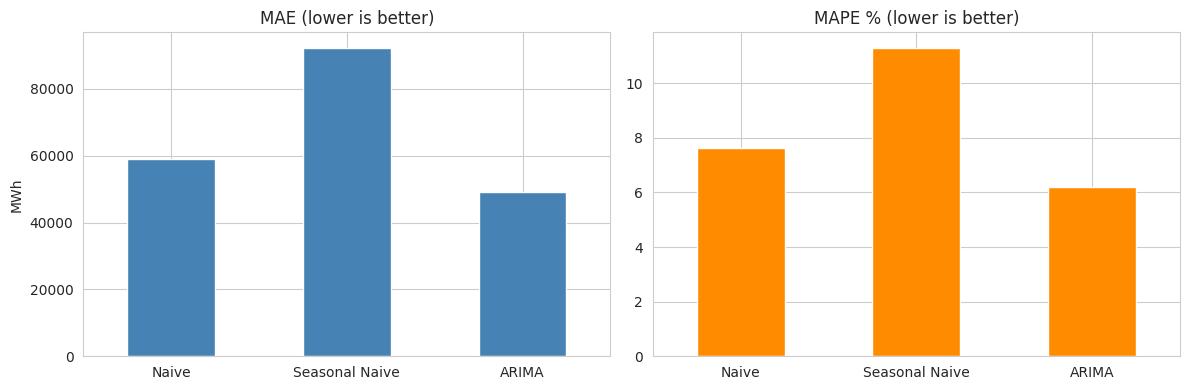

In [ ]:
model_order = ['Naive', 'Seasonal Naive', 'ARIMA']

# Safety check: every model predicts the same test days, with no missing values
for name in model_order:
    assert predictions[name].index.equals(test.index), f"{name}: dates do not match the test period"
    assert predictions[name].isnull().sum() == 0, f"{name}: contains missing values"

results_df = pd.DataFrame(results).T.loc[model_order, ['MAE', 'RMSE', 'MAPE (%)']]
display(results_df.round(3))

naive_mae = results_df.loc['Naive', 'MAE']
change = ((results_df['MAE'] / naive_mae - 1) * 100).drop('Naive').round(1)
print("Change in MAE compared with the Naive baseline (negative = better):")
print(change.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results_df['MAE'].plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('MAE (lower is better)')
axes[0].set_ylabel('MWh')
results_df['MAPE (%)'].plot(kind='bar', ax=axes[1], color='darkorange', rot=0)
axes[1].set_title('MAPE % (lower is better)')
plt.tight_layout()
plt.show()

## 10. Actual vs Predicted

One graph per model on the test period. A good forecast line hugs the actual line, including the weekly ups and downs. The Naive line looks like the actual line **shifted one day later**, because it simply repeats yesterday.

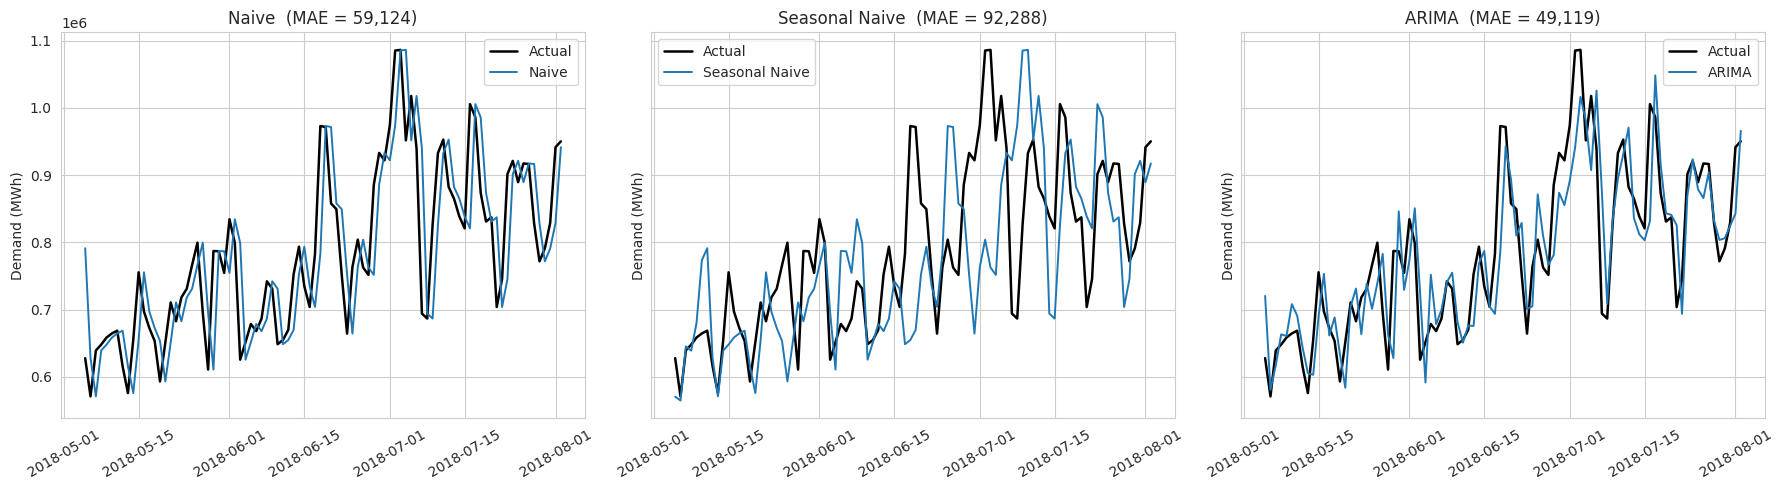

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), model_order):
    ax.plot(test.index, test.values, label='Actual', color='black', linewidth=1.8)
    ax.plot(test.index, predictions[name].values, label=name, linewidth=1.4)
    ax.set_title(f"{name}  (MAE = {results[name]['MAE']:,.0f})")
    ax.set_ylabel('Demand (MWh)')
    ax.legend()
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

All Forecasts Overlaid

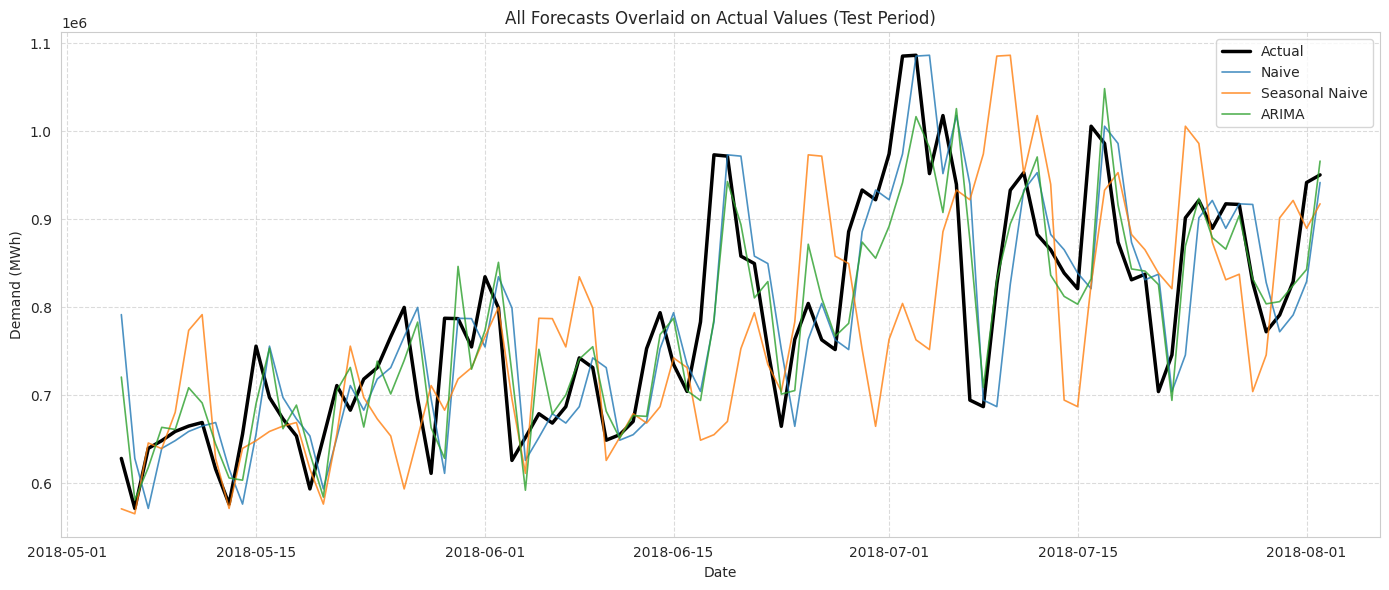

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(test.index, test.values, label='Actual', color='black', linewidth=2.5)

for name in model_order:
    plt.plot(test.index, predictions[name].values, label=name, linewidth=1.2, alpha=0.8)

plt.title('All Forecasts Overlaid on Actual Values (Test Period)')
plt.xlabel('Date')
plt.ylabel('Demand (MWh)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 11. Residual Analysis

**Residual = actual - predicted.** A good model leaves residuals that look like random noise: centred around zero (no systematic over- or under-forecasting) and with no obvious remaining pattern. A visible pattern means the model missed some information.

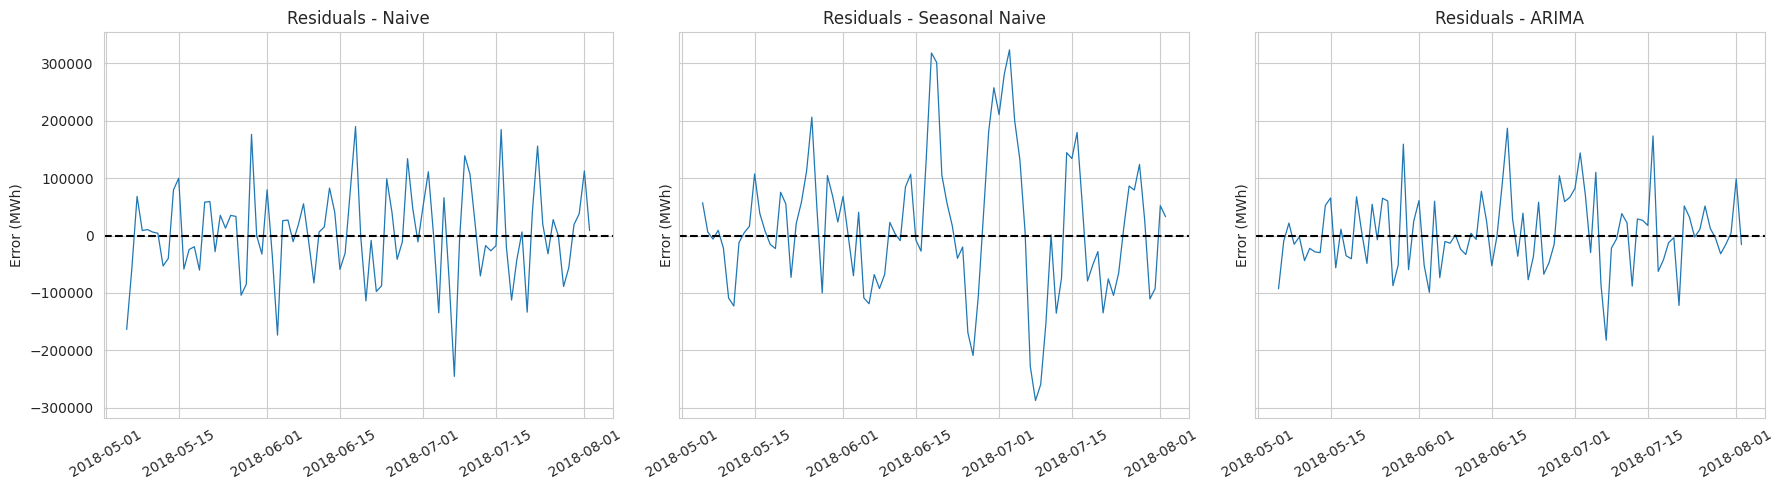

,Mean residual (bias),Std of residual
Naive,1765.0,78991.0
Seasonal Naive,15140.0,121897.0
ARIMA,4727.0,64336.0


In [ ]:
residuals = {name: test - predictions[name] for name in model_order}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), model_order):
    ax.plot(residuals[name].index, residuals[name].values, linewidth=0.9)
    ax.axhline(0, color='black', linestyle='--')
    ax.set_title(f'Residuals - {name}')
    ax.set_ylabel('Error (MWh)')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

residual_summary = pd.DataFrame({
    name: {'Mean residual (bias)': r.mean(), 'Std of residual': r.std()} for name, r in residuals.items()
}).T
display(residual_summary.round(0))

**Residuals overlaid on one graph**

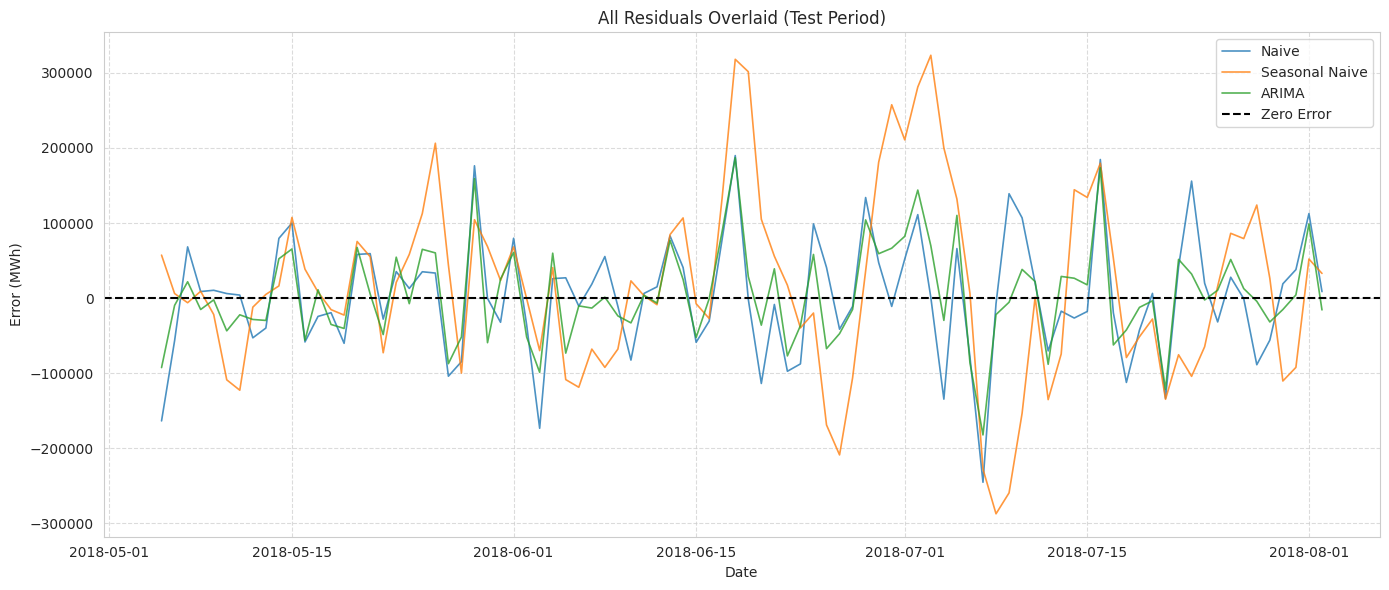

In [ ]:
plt.figure(figsize=(14, 6))

for name in model_order:
    plt.plot(residuals[name].index, residuals[name].values, label=name, linewidth=1.2, alpha=0.8)

plt.axhline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
plt.title('All Residuals Overlaid (Test Period)')
plt.xlabel('Date')
plt.ylabel('Error (MWh)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 12. Conclusion

In [ ]:
best_mae = results_df['MAE'].idxmin()
best_mape = results_df['MAPE (%)'].idxmin()

print(f"Lowest MAE:  {best_mae} ({results_df.loc[best_mae, 'MAE']:,.0f} MWh)")
print(f"Lowest MAPE: {best_mape} ({results_df.loc[best_mape, 'MAPE (%)']:.2f} %)")
print(f"\nBest model vs Naive baseline: MAE change = {(results_df.loc[best_mae, 'MAE'] / naive_mae - 1) * 100:+.1f} %")

Lowest MAE:  ARIMA (49,119 MWh)
Lowest MAPE: ARIMA (6.21 %)

Best model vs Naive baseline: MAE change = -16.9 %


**What to take away**

* The two baselines set the reference line. ARIMA is only worth using if it beats them clearly.
* ARIMA uses only the past values (and past errors) of the demand series, with up to 7 AR lags so it can pick up the weekly cycle. It beats both baselines on every metric here.
* The Seasonal Naive baseline (same weekday last week) is the weakest model on this test window, even weaker than the plain Naive baseline.
* The part no model explains is mostly **weather**, which is not in this dataset.

**Limitations:** one test window of 90 days (May to August); no weather or holiday data; forecasts are one day ahead only; ARIMA is a linear model on the daily series and does not use calendar features.
